# Solow Growth Model Analysis
This notebook examines how the Solow steady-state model behaves under different types of shocks. It also provides an empirical test of the model using data from Penn World Table 11.0.

### Importing libraries

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import statsmodels.api as sm

### Defining the model
The steady-state level of income per capita is given by:

$$
y^* = A\left(\frac{s}{n+g+\delta}\right)^{\frac{\alpha}{1-\alpha}}
$$

where:

- $y$ = steady-state income per capita
- $A$ = level of technology
- $s$ = investment (saving) rate
- $n$ = population growth rate
- $g$ = technological growth rate
- $\delta$ = depreciation rate of capital
- $\alpha$ = capital share of income

In [2]:
def y_ss(A, s, n, g, delta, alpha):

    y = A * (s / (n + g + delta))**(alpha / (1-alpha))

    return y

#Standard values for the exogenous variables
A = 1
s = 0.1
n = 0.01
g = 0.015
delta = 0.05
alpha = 0.33

## Simulation 1: Population Growth Shock 

In [3]:
shock_n = np.linspace(start = -0.05, stop = 0, num = 51) #num = np.abs(((0-0.05)/0.001))+1

In [4]:
effect_n = y_ss(A = A, s = s, n = shock_n, g = g, delta = delta, alpha = alpha)

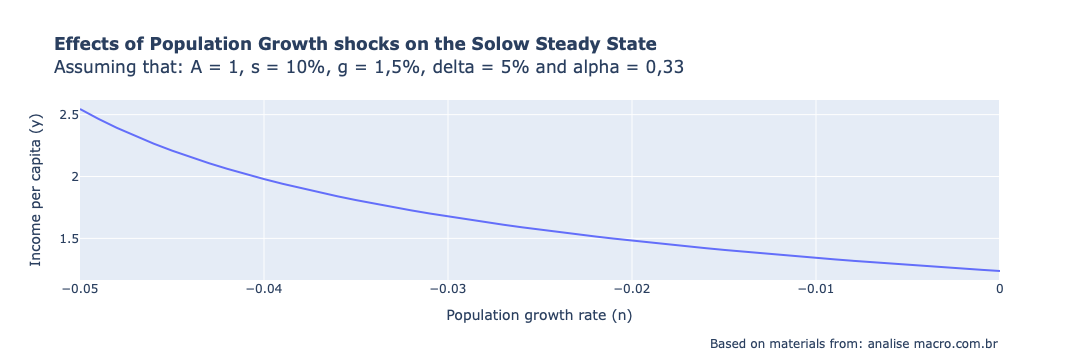

In [5]:
px.line(
    x = shock_n,
    y = effect_n,
    labels = dict(
        x = "Population growth rate (n)",
        y = "Income per capita (y)"
        ),
    title = "<b>Effects of Population Growth shocks on the Solow Steady State</b>" +
    "<br>Assuming that: A = 1, s = 10%, g = 1,5%, delta = 5% and alpha = 0,33"
    ).add_annotation(
    showarrow = False,
    text = "Based on materials from: analise macro.com.br",
    x = 1,
    xref = "paper",
    y = -0.4,
    yref = "paper",
    align = "right"
    )

As expected by the model, it is possible to identify a negative relation between population growth rate and income per capita

## Simulation 2: Savings Rate Shock

In [6]:
shock_s = np.linspace(start = 0.1, stop = 0.5, num = 41)

In [7]:
effect_s = y_ss(A = A, s = shock_s, n = n, g = g, delta = delta, alpha = alpha)

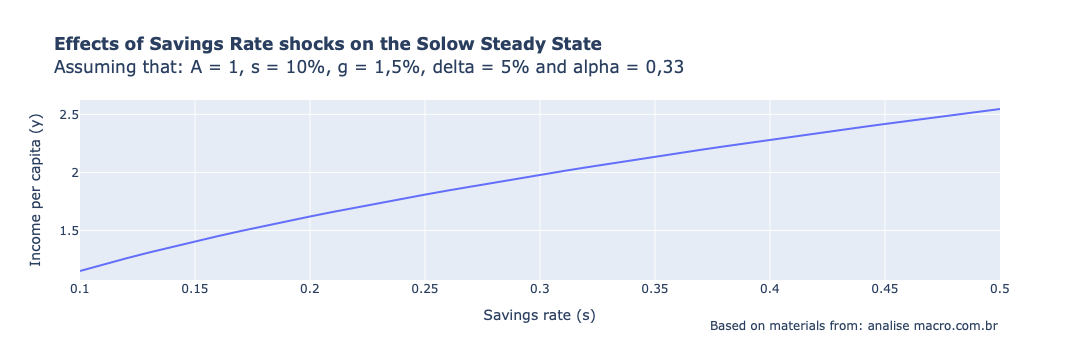

In [8]:
px.line(
    x = shock_s,
    y = effect_s,
    labels = dict(
        x = "Savings rate (s)",
        y = "Income per capita (y)"
        ),
    title = "<b>Effects of Savings Rate shocks on the Solow Steady State</b>" +
    "<br>Assuming that: A = 1, s = 10%, g = 1,5%, delta = 5% and alpha = 0,33"
    ).add_annotation(
    showarrow = False,
    text = "Based on materials from: analise macro.com.br",
    x = 1,
    xref = "paper",
    y = -0.3,
    yref = "paper",
    align = "right"
    )

As predicted by the model, there is a positive relationship between the savings rate and income per capita.

## Simulation 3:

In [9]:
shock_A = np.linspace(start = 1.05, stop = 2.5, num = 146)

In [10]:
effect_A = y_ss(A = shock_A, s = s, n = n, g = g, delta = delta, alpha = alpha)

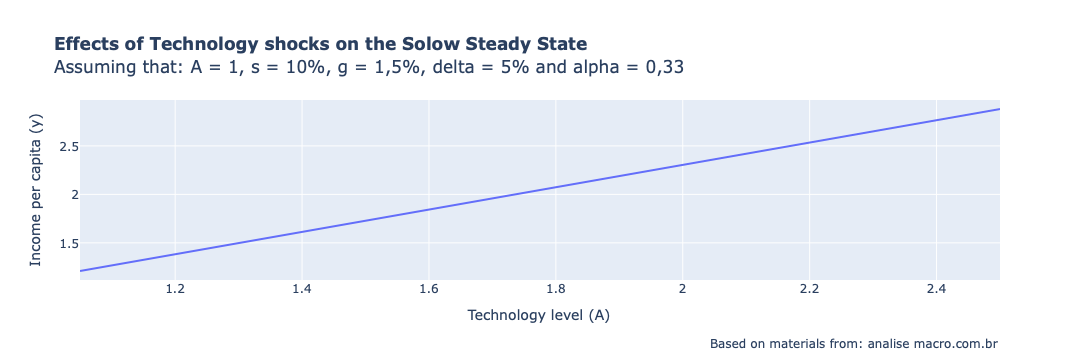

In [11]:
px.line(
    x = shock_A,
    y = effect_A,
    labels = dict(
        x = "Technology level (A)",
        y = "Income per capita (y)"
        ),
    title = "<b>Effects of Technology shocks on the Solow Steady State</b>" +
    "<br>Assuming that: A = 1, s = 10%, g = 1,5%, delta = 5% and alpha = 0,33"
    ).add_annotation(
    showarrow = False,
    text = "Based on materials from: analise macro.com.br",
    x = 1,
    xref = "paper",
    y = -0.4,
    yref = "paper",
    align = "right"
    )

As expected by the model, it is possible to identify a positive relation between technology level and income per capita

## Plotting the solow diagram
Calculating capital per capita from income per capita

Note that the production function is:
$$
y = k^{\alpha}
$$
Therefore, we can recover capital per capita from income per capita:
$$
k = y^{\frac{1}{\alpha}}
$$
Once we obtain $k$, we can also compute the depreciation line:
$$
(n + g + \delta)k
$$
and the investment curve:
$$
s y
$$

In [12]:
solow = pd.DataFrame()
solow["y"] = effect_s
solow["s"] = shock_s
solow["k"] = solow["y"]**(1/alpha)
solow["n_g_delta_k"] = (n + g + delta) * solow["k"]
solow["sy"] = np.mean(shock_s) * solow["y"] 

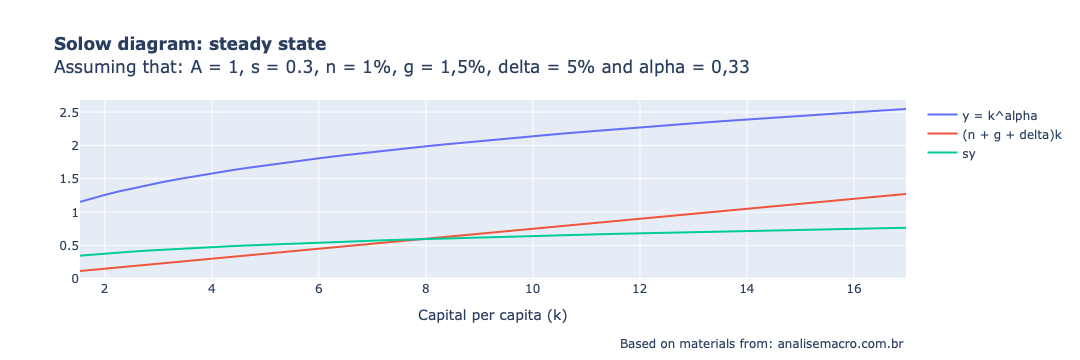

In [13]:
g1 = go.Figure()

g1.add_trace(
    go.Scatter(x = solow["k"], y = solow["y"], mode = "lines", name = "y = k^alpha")
)
g1.add_trace(
    go.Scatter(x = solow["k"], y = solow["n_g_delta_k"], mode = "lines", name = "(n + g + delta)k")
)
g1.add_trace(
    go.Scatter(x = solow["k"], y = solow["sy"], mode = "lines", name = "sy")
)

g1.update_layout(
    title = "<b>Solow diagram: steady state</b><br>" +
    "Assuming that: A = 1, s = " + str(np.round(a = np.mean(shock_s), decimals = 1)) +
    ", n = 1%, g = 1,5%, delta = 5% and alpha = 0,33",
    xaxis_title = "Capital per capita (k)"
)

g1.add_annotation(
    showarrow = False,
    text = "Based on materials from: analisemacro.com.br",
    x =1,
    xref = "paper",
    y = -0.4,
    yref = "paper",
    align = "right"
)

# Empirical analysis

We now test the model using real data from Penn World Table 11.0.

First, we load and clean the dataset.

Next, we construct a population growth variable.

Finally, we apply a filter to keep only countries with more than 20 observations.


In [14]:
df = pd.read_csv("pwt.csv")

df = df.drop(columns=["iso3"])

df = df.rename(columns={
    "cn":"capital",
    "csh_i":"investment_share",
    "pop":"population",
    "rgdpe":"gdp"
})

df = df.sort_values(["Country","year"])

df["k"] = df["capital"] / df["population"]
df["y"] = df["gdp"] / df["population"]

df["n"] = df.groupby("Country")["population"].pct_change()

df = df.dropna()

df = df.groupby("Country").filter(lambda x: len(x) > 20)

df

,Country,year,capital,investment_share,population,gdp,k,y,n
163,Albania,1971,24193.527344,0.190628,2.234992,7464.951172,10824.883196,3340.034851,0.024652
164,Albania,1972,25761.890625,0.192282,2.289265,7765.654297,11253.345779,3392.204178,0.024283
165,Albania,1973,27382.001953,0.196259,2.344105,8075.945801,11681.218185,3445.215040,0.023955
166,Albania,1974,29102.287109,0.199975,2.399401,8399.456055,12128.980154,3500.647059,0.023589
167,Albania,1975,30842.578125,0.204285,2.454859,8738.759766,12563.889871,3559.780731,0.023113
...,...,...,...,...,...,...,...,...,...
11196,Zimbabwe,2019,83138.546875,0.130147,15.271368,46541.140625,5444.079854,3047.607826,0.015758
11197,Zimbabwe,2020,86924.070312,0.119450,15.526888,45985.085938,5598.293123,2961.642149,0.016732
11198,Zimbabwe,2021,110979.773438,0.153113,15.797210,45625.347656,7025.276833,2888.190235,0.017410
11199,Zimbabwe,2022,114640.703125,0.172489,16.069056,50148.527344,7134.252511,3120.813528,0.017208


Since the model focuses on the steady state, let's create a new data frame using the average value of each variable for each country.

In [15]:
df_avg = df.groupby("Country").mean(numeric_only=True).reset_index()

df_avg

,Country,year,capital,investment_share,population,gdp,k,y,n
0,Albania,1997.0,9.861247e+04,0.201319,2.939116,20033.741294,33593.381618,6838.446523,0.004882
1,Algeria,1992.0,1.437296e+06,0.340839,26.491927,328588.423673,50357.346569,11497.500990,0.023372
2,Angola,1997.0,4.738209e+05,0.332382,17.022783,96647.982201,24482.819326,5006.620739,0.035276
3,Anguilla,1997.0,2.213888e+03,0.554690,0.010276,288.274997,196919.213664,25924.416390,0.015854
4,Antigua and Barbuda,1997.0,5.338135e+03,0.252758,0.074550,1335.873590,62315.361503,16965.198739,0.007015
...,...,...,...,...,...,...,...,...,...
175,Venezuela (Bolivarian Republic of),1987.0,7.103430e+05,0.276902,18.538699,174389.378174,35341.054507,9458.236264,0.023320
176,Viet Nam,1997.0,9.640982e+05,0.174807,72.609535,356696.269384,10612.323732,4128.821185,0.016828
177,Yemen,2006.5,2.447367e+05,0.157677,24.973703,49476.773840,7964.493467,1909.591857,0.032308
178,Zambia,1989.5,1.054756e+05,0.140509,8.981207,24757.926916,9342.603271,2699.453075,0.029263


We are going to create a new variable to the $ n + g + \delta $ term

In [16]:
g = 0.015
delta = 0.05

df_avg["ngd"] = df_avg["n"] + g + delta

It is important to note that this term mainly captures the effect of population growth on income per capita, since $g$ and $\delta$ are assumed to be constant across countries.

### Log-linearizing the model:
$$
log(y^*) = log(A) + \frac{\alpha}{1-\alpha} log(s) - \frac{\alpha}{1-\alpha}log(n + g + \delta)
$$

We can transform that to:

$$
log(y^*) = \beta_0 + \beta_1 log(s) + \beta_2 log(n + g + \delta)
$$

In [17]:
df_avg['log_y'] = np.log(df_avg['y'])
df_avg['log_s'] = np.log(df_avg['investment_share'])
df_avg['log_ngd'] = np.log(df_avg['ngd'])
df_avg

,Country,year,capital,investment_share,population,gdp,k,y,n,ngd,log_y,log_s,log_ngd
0,Albania,1997.0,9.861247e+04,0.201319,2.939116,20033.741294,33593.381618,6838.446523,0.004882,0.069882,8.830316,-1.602865,-2.660941
1,Algeria,1992.0,1.437296e+06,0.340839,26.491927,328588.423673,50357.346569,11497.500990,0.023372,0.088372,9.349885,-1.076344,-2.426203
2,Angola,1997.0,4.738209e+05,0.332382,17.022783,96647.982201,24482.819326,5006.620739,0.035276,0.100276,8.518516,-1.101470,-2.299831
3,Anguilla,1997.0,2.213888e+03,0.554690,0.010276,288.274997,196919.213664,25924.416390,0.015854,0.080854,10.162941,-0.589346,-2.515107
4,Antigua and Barbuda,1997.0,5.338135e+03,0.252758,0.074550,1335.873590,62315.361503,16965.198739,0.007015,0.072015,9.738919,-1.375322,-2.630878
...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,Venezuela (Bolivarian Republic of),1987.0,7.103430e+05,0.276902,18.538699,174389.378174,35341.054507,9458.236264,0.023320,0.088320,9.154641,-1.284093,-2.426785
176,Viet Nam,1997.0,9.640982e+05,0.174807,72.609535,356696.269384,10612.323732,4128.821185,0.016828,0.081828,8.325747,-1.744072,-2.503139
177,Yemen,2006.5,2.447367e+05,0.157677,24.973703,49476.773840,7964.493467,1909.591857,0.032308,0.097308,7.554645,-1.847207,-2.329874
178,Zambia,1989.5,1.054756e+05,0.140509,8.981207,24757.926916,9342.603271,2699.453075,0.029263,0.094263,7.900804,-1.962484,-2.361670


In [18]:
X = df_avg[['log_s','log_ngd']]
X = sm.add_constant(X)

In [19]:
Y = df_avg['log_y']

In [20]:
model = sm.OLS(Y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  log_y   R-squared:                       0.405
Model:                            OLS   Adj. R-squared:                  0.399
Method:                 Least Squares   F-statistic:                     60.33
Date:                Tue, 10 Mar 2026   Prob (F-statistic):           1.05e-20
Time:                        17:02:46   Log-Likelihood:                -226.01
No. Observations:                 180   AIC:                             458.0
Df Residuals:                     177   BIC:                             467.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.9634      1.024      6.798      0.0

The estimation results show a positive relationship between investment and income per capita, and a negative relationship between population growth and income per capita.

We now plot these relationships for a better visual interpretation.

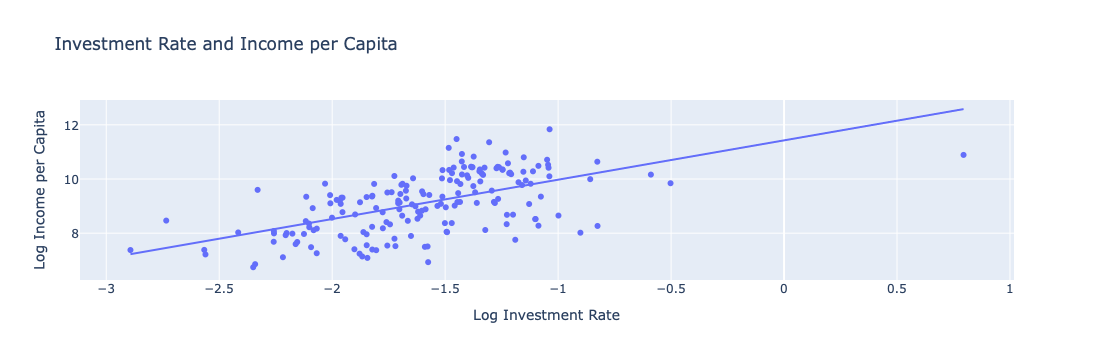

In [21]:
px.scatter(
    df_avg,
    x="log_s",
    y="log_y",
    hover_name="Country",
    trendline="ols",
    title="Investment Rate and Income per Capita",
    labels={
        "log_s": "Log Investment Rate",
        "log_y": "Log Income per Capita"
    }
)

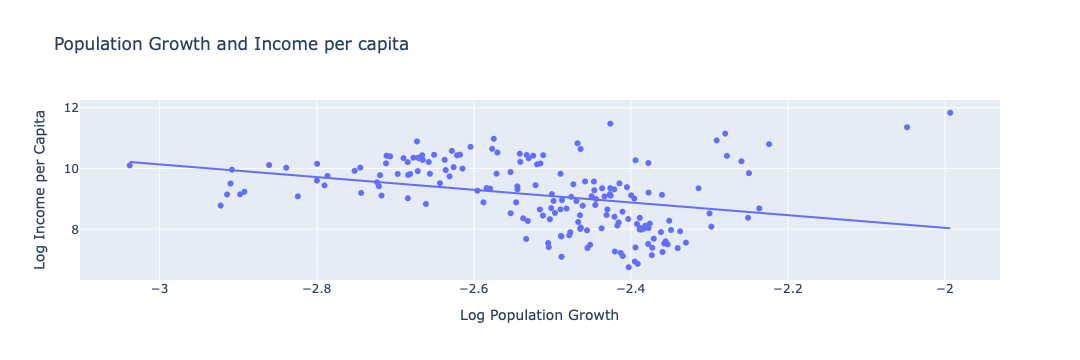

In [22]:
px.scatter(
    df_avg,
    x = 'log_ngd',
    y = 'log_y',
    hover_name = 'Country',
    trendline = 'ols',
    title = 'Population Growth and Income per capita',
    labels={
        'log_ngd': 'Log Population Growth',
        'log_y': 'Log Income per Capita'
    }
)

## Predicted Income vs Observed Income

It is also useful to compare the income per capita predicted by the model with the actual observed values.

In [23]:
df_avg["log_y_pred"] = model.predict(X)

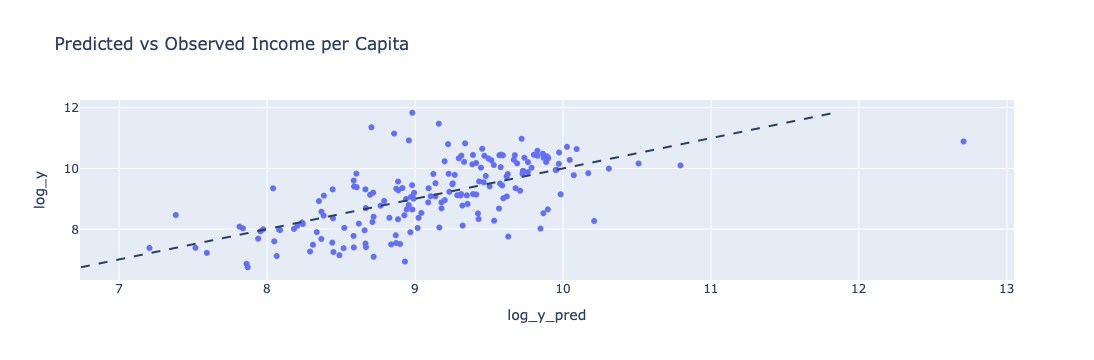

In [24]:
fig = px.scatter(
    df_avg,
    x="log_y_pred",
    y="log_y",
    hover_name="Country",
    title="Predicted vs Observed Income per Capita"
)

fig.add_shape(
    type="line",
    x0=df_avg["log_y"].min(),
    y0=df_avg["log_y"].min(),
    x1=df_avg["log_y"].max(),
    y1=df_avg["log_y"].max(),
    line=dict(dash="dash")
)

fig.show()

Overall, although the model is relatively simple, the predicted values are reasonably close to the observed ones.


# Augmented Solow model with human capital

Mankiw, Romer and Weil (1992) extend the Solow model by adding human capital $H$ as a third accumulable factor:

$$
Y = K^{\alpha} H^{\beta} (AL)^{1-\alpha-\beta}, \qquad \alpha + \beta < 1
$$

When the stock of human capital per effective worker, $h^*$, is observed, the steady state can be written as:

$$
\log(y^*) = \log(A) + \frac{\alpha}{1-\alpha}\log(s) - \frac{\alpha}{1-\alpha}\log(n+g+\delta) + \frac{\beta}{1-\alpha}\log(h^*)
$$

The restriction $\beta_1 + \beta_2 = 0$ still holds. With $\alpha = \beta = 1/3$, the coefficients on $\log(s)$ and $\log(h)$ should both be close to $0.5$.

Omitting $h$ biases the coefficient on $\log(s)$ upwards whenever investment and human capital are positively correlated across countries, which is the explanation MRW give for the high capital share implied by the textbook model.

### Human capital data

Penn World Table 11.0 provides `hc`, an index of human capital per person based on average years of schooling, mainly from Barro and Lee (2013), and on Mincerian rates of return to education (Psacharopoulos, 1994). The file `pwt_hc.csv` contains this series, extracted from `pwt110.dta`.

The index is merged with the same country-year observations used above and averaged by country. Only countries with more than 20 annual observations of `hc` are kept.

In [25]:
hc = pd.read_csv("pwt_hc.csv")

df_hc = df.merge(hc[["Country", "year", "hc"]], on=["Country", "year"], how="left")

hc_avg = df_hc.groupby("Country")["hc"].agg(hc="mean", hc_obs="count").reset_index()

df_aug = df_avg.merge(hc_avg, on="Country")
df_aug = df_aug[df_aug["hc_obs"] > 20].copy()
df_aug["log_h"] = np.log(df_aug["hc"])

print("Countries in the baseline sample:", len(df_avg))
print("Countries with human capital data:", len(df_aug))

Countries in the baseline sample: 180
Countries with human capital data: 144


MRW report their main results for a sample that excludes oil producers, whose income comes mostly from natural resources rather than from capital accumulation. We estimate both models on the sample with human capital data and on that sample without oil exporters.

In [26]:
oil = [
    "Algeria", "Angola", "Bahrain", "Brunei Darussalam", "Equatorial Guinea", "Gabon",
    "Iran (Islamic Republic of)", "Iraq", "Kuwait", "Nigeria", "Oman", "Qatar",
    "Saudi Arabia", "Trinidad and Tobago", "United Arab Emirates",
    "Venezuela (Bolivarian Republic of)"
]

df_aug_nonoil = df_aug[~df_aug["Country"].isin(oil)].copy()

print("Countries without oil exporters:", len(df_aug_nonoil))

Countries without oil exporters: 130


In [27]:
def estimate(data, human_capital):
    regressors = ["log_s", "log_ngd"] + (["log_h"] if human_capital else [])
    unrestricted = sm.OLS(data["log_y"], sm.add_constant(data[regressors])).fit()
    p_restriction = float(unrestricted.f_test("log_s + log_ngd = 0").pvalue)

    restricted_X = pd.DataFrame({"log_s_minus_ngd": data["log_s"] - data["log_ngd"]})
    if human_capital:
        restricted_X["log_h"] = data["log_h"]
    restricted = sm.OLS(data["log_y"], sm.add_constant(restricted_X)).fit()

    b = restricted.params["log_s_minus_ngd"]
    alpha_hat = b / (1 + b)
    beta_hat = restricted.params["log_h"] * (1 - alpha_hat) if human_capital else np.nan

    return unrestricted, restricted, {
        "N": int(unrestricted.nobs),
        "log_s": unrestricted.params["log_s"],
        "log_ngd": unrestricted.params["log_ngd"],
        "log_h": unrestricted.params.get("log_h", np.nan),
        "R2": unrestricted.rsquared,
        "p-value (b1 + b2 = 0)": p_restriction,
        "implied alpha": alpha_hat,
        "implied beta": beta_hat,
    }

results = {}
models = {}
for label, data in [("With hc data", df_aug), ("Without oil exporters", df_aug_nonoil)]:
    for name, hk in [("Solow", False), ("Augmented", True)]:
        unrestricted, restricted, row = estimate(data, hk)
        results[(label, name)] = row
        models[(label, name)] = (unrestricted, restricted)

comparison = pd.DataFrame(results).T
comparison.round(3)

N  log_s  log_ngd  log_h     R2  \
With hc data          Solow      144.0  1.748   -2.105    NaN  0.470   
                      Augmented  144.0  0.886    1.405  2.897  0.746   
Without oil exporters Solow      130.0  1.502   -3.590    NaN  0.631   
                      Augmented  130.0  0.853   -0.350  2.301  0.791   

                                 p-value (b1 + b2 = 0)  implied alpha  \
With hc data          Solow                      0.478          0.644   
                      Augmented                  0.000          0.450   
Without oil exporters Solow                      0.000          0.654   
                      Augmented                  0.278          0.454   

                                 implied beta  
With hc data          Solow               NaN  
                      Augmented         1.215  
Without oil exporters Solow               NaN  
                      Augmented         1.177

In [28]:
print(models[("Without oil exporters", "Augmented")][0].summary())

                            OLS Regression Results                            
Dep. Variable:                  log_y   R-squared:                       0.791
Model:                            OLS   Adj. R-squared:                  0.786
Method:                 Least Squares   F-statistic:                     158.5
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.35e-42
Time:                        10:42:59   Log-Likelihood:                -95.841
No. Observations:                 130   AIC:                             199.7
Df Residuals:                     126   BIC:                             211.2
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.8256      1.058      7.399      0.0

In [29]:
aug_nonoil = models[("Without oil exporters", "Augmented")][0]
robust = sm.OLS(df_aug_nonoil["log_y"], sm.add_constant(df_aug_nonoil[["log_s", "log_ngd", "log_h"]])).fit(cov_type="HC1")
pd.DataFrame({"coef": aug_nonoil.params, "se (OLS)": aug_nonoil.bse, "se (HC1)": robust.bse}).round(3)

,coef,se (OLS),se (HC1)
const,7.826,1.058,1.089
log_s,0.853,0.140,0.184
log_ngd,-0.350,0.463,0.515
log_h,2.301,0.235,0.297


Adding human capital changes the results in the direction predicted by MRW. The coefficient on $\log(s)$ falls by about 40%, and the implied capital share drops from about 0.65 to about 0.45. In the sample without oil exporters, the model explains about 79% of the cross-country variance of log income, against 63% without human capital, and the restriction $\beta_1 + \beta_2 = 0$ is not rejected.

Two results do not match the theory. In the sample that includes oil exporters, the coefficient on $\log(n+g+\delta)$ becomes positive: Gulf economies combine high income, high schooling and fast population growth driven by immigration. The coefficient on $\log(h)$ is also much larger than 0.5, and the implied $\beta$ is above 1, which would violate $\alpha + \beta < 1$. The `hc` index measures labor efficiency from years of schooling, not a stock of human capital in units of output as in MRW, and it is strongly correlated with the omitted technology term $A$. Its coefficient should therefore not be read as a structural estimate of $\beta$.

In [30]:
restricted_t = models[("Without oil exporters", "Augmented")][1]
coef_h = restricted_t.params["log_h"]
se_h = restricted_t.bse["log_h"]
print(f"Coefficient on log(h), restricted model: {coef_h:.3f} (se {se_h:.3f})")
print(f"t-statistic for H0: coefficient = 0.5 -> {(coef_h - 0.5) / se_h:.2f}")
print(f"t-statistic for H0: coefficient = 1.0 -> {(coef_h - 1.0) / se_h:.2f}")

Coefficient on log(h), restricted model: 2.155 (se 0.193)
t-statistic for H0: coefficient = 0.5 -> 8.59
t-statistic for H0: coefficient = 1.0 -> 6.00


In [31]:
df_aug_nonoil["pred_solow"] = models[("Without oil exporters", "Solow")][0].fittedvalues
df_aug_nonoil["pred_augmented"] = models[("Without oil exporters", "Augmented")][0].fittedvalues

plot_df = pd.concat([
    df_aug_nonoil[["Country", "log_y", "pred_solow"]].rename(columns={"pred_solow": "log_y_pred"}).assign(model="Solow"),
    df_aug_nonoil[["Country", "log_y", "pred_augmented"]].rename(columns={"pred_augmented": "log_y_pred"}).assign(model="Augmented Solow"),
])

fig = px.scatter(
    plot_df,
    x="log_y_pred",
    y="log_y",
    color="model",
    hover_name="Country",
    title="Predicted vs Observed Income per Capita: Solow and Augmented Solow (without oil exporters)",
    labels={"log_y_pred": "Predicted log income per capita", "log_y": "Observed log income per capita"}
)
lo, hi = plot_df[["log_y", "log_y_pred"]].min().min(), plot_df[["log_y", "log_y_pred"]].max().max()
fig.add_shape(type="line", x0=lo, y0=lo, x1=hi, y1=hi, line=dict(dash="dash"))
fig.show()

Including human capital moves most countries closer to the 45-degree line. The model still leaves a large part of income differences unexplained, which is consistent with development accounting studies that attribute most of the gap to total factor productivity (Hall and Jones, 1999; Caselli, 2005).

## References

- Barro, R. J. and Lee, J. W. (2013) – A New Data Set of Educational Attainment in the World, 1950–2010. Journal of Development Economics, 104, 184-198
- Caselli, F. (2005) – Accounting for Cross-Country Income Differences. Handbook of Economic Growth, 1A, 679-741
- Feenstra, Robert C., Robert Inklaar and Marcel P. Timmer (2015), "The Next Generation of the Penn World Table" American Economic Review, 105(10), 3150-3182, available for download at www.ggdc.net/pwt
- Hall, R. E. and Jones, C. I. (1999) – Why Do Some Countries Produce So Much More Output per Worker than Others? Quarterly Journal of Economics, 114(1), 83-116
- Mankiw, Romer & Weil (1992) – A Contribution to the Empirics of Economic Growth
- Psacharopoulos, G. (1994) – Returns to Investment in Education: A Global Update. World Development, 22(9), 1325-1343
- Solow (1956) – A Contribution to the Theory of Economic Growth